## Demo Diffusion models generative AI

Author: alberto.suarez@uam.es
Date: 2025-03-02

In [1]:
%load_ext autoreload
%autoreload 2

import numpy as np

from functools import partial 

import torch
from torch.utils.data import (
    DataLoader,
    Dataset,
    Subset,
)
from torchvision import datasets
from torchvision.transforms import ToTensor
from torchvision.transforms import functional

import diffusion_process as dfp
import difussion_process_conditional as dfpc
import ode as ode
import ode_condicional as odec


from diffusion_utilities import (
    plot_image_grid,
    plot_image_evolution,
    animation_images,
    colorize_mnist
)


n_threads = torch.get_num_threads()
print('Number of threads: {:d}'.format(n_threads))

device ='cuda' #with cuda should be faster
#device ='cpu' 

colored = True


Number of threads: 6


In [2]:
import torchvision.transforms as T
if not colored:
    transform = ToTensor()
    n_channels = 1
else:
    # Convierte a (1, H, W) y luego colorea a (3, H, W)
    transform = T.Compose([
        ToTensor(),
        T.Lambda(colorize_mnist),
    ])
    n_channels = 3
data = datasets.MNIST(
    root='data',
    train=True,
    download=True,
    transform=transform,
)
print(type(data))


<class 'torchvision.datasets.mnist.MNIST'>


In [3]:
# Create a subset dataset composed of only images of one of the digits
digit1 = 3
digit2 = 8
indices_digit = torch.where(
    (data.targets == digit1) | (data.targets == digit2)
)[0]
#indices_digit = torch.where(data.targets == digit1)[0]  

data_train = data
print(type(data_train))

<class 'torchvision.datasets.mnist.MNIST'>


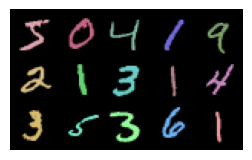

In [4]:
# Visualize training images
n_rows = 3 
n_cols = 5

_ = plot_image_grid(
    images=[data_train[i][0] for i in range(n_rows * n_cols)],
    figsize =(3, 3),
    n_rows=n_rows, 
    n_cols=n_cols,
)

###  Diffusion process

In [5]:
#sigma = 25.0
sigma_min = 0.01
sigma_max = 50.0

def bm_drift_coefficient(x_t, t): 
    return 0.0

def bm_sigma_t(t):
    t = torch.tensor(t)
    t = t.float()
    return sigma_min*(sigma_max/sigma_min)**t

def bm_diffusion_coefficient(t):
    sigma_t_val = bm_sigma_t(t)
    result = sigma_t_val * torch.sqrt(2 * torch.log(torch.tensor(sigma_max / sigma_min)))
    return result.view(-1,1,1,1)

def bm_mu_t(x_0, t):
    return x_0

    
def ve_marginal_prob_std(t):
    return bm_sigma_t(t)

drift_coefficient = bm_drift_coefficient
diffusion_coefficient = bm_diffusion_coefficient
mu_t = bm_mu_t
sigma_t = bm_sigma_t


diffusion_process = dfpc.GaussianDiffussionProcess(
    drift_coefficient,
    diffusion_coefficient,
    mu_t,
    sigma_t,
)


In [6]:
# Define the score model

from score_model import ScoreNet

score_model = torch.nn.DataParallel(
    ScoreNet(
        marginal_prob_std=ve_marginal_prob_std,
        num_classes=10,
        input_channels = n_channels
    )
)
score_model = score_model.to(device)

In [44]:
# Train model
from torch.optim import Adam
import torchvision.transforms as transforms
from tqdm.auto import tqdm, trange
batch_size = 32
data_loader = DataLoader(
    data_train, 
    batch_size=batch_size, 
    shuffle=True, 
    num_workers=n_threads,
)
"""
checkpoint = torch.load('check_point_VE_euler.pth')
score_model.load_state_dict(checkpoint)
"""
#  [TO DO: Comment each line of code]
#establish learning rate, which controls the size of the weights
learning_rate = 1e-3  
# We create Adam optimizer which adjusts automatically the learning rate for each parameter. 
# score_model, tells the optimizer which weights to use
# lr, defines the learning rate
optimizer = Adam(score_model.parameters(), lr=learning_rate)
n_epochs =  50 #Number of epochs for training
tqdm_epoch = trange(n_epochs) #creates a progress bar to see the progress of the training
for epoch in tqdm_epoch: 
    avg_loss = 0.0 #Initial average loss
    num_items = 0 #Number of images processed in an epoch
    for x, y in data_loader: #for each bacth the data_loader
        x = x.to(device) #images to cpu or gpu for PyTorch to process them
        y = y.to(device)
        loss = diffusion_process.loss_function(score_model, x, y) #loss for the batch
        optimizer.zero_grad() #reboot gradients to zero (if not they acumulate)
        loss.backward() #calcules the loss gradients in respect of all the parameters
        optimizer.step() #updates the parameters using the gradient
        avg_loss += loss.item() * x.shape[0] #Sum of total loss
        num_items += x.shape[0] #Sum of all the images processed
       
    #Updates the progress bar showing the mean loss
    tqdm_epoch.set_description('Average Loss: {:5f}'.format(avg_loss / num_items))
    #Save the weights of the trained model
    torch.save(score_model.state_dict(), 'check_point_VE_euler.pth')

  0%|          | 0/50 [00:00<?, ?it/s]

/tmp/ipykernel_8566/964758059.py:9: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  t = torch.tensor(t)
Average Loss: 0.034050: 100%|██████████| 50/50 [16:02<00:00, 19.26s/it]


In [7]:
# Sample from the trained model

n_images = 10

check_point = torch.load('check_point_VE_euler.pth', map_location=device)
score_model.load_state_dict(check_point)

T = 1.0
image_T = torch.randn(n_images, n_channels, 28, 28).to(device) * sigma_t(T)

y = torch.tensor([i for i in range(10)], device=device)

# t_end pequeño reduce el ruido residual:
# sigma_residual(t_end) = sigma * sqrt(t_end)
# t_end=0.02  -> sigma_residual ≈ 2.12  (MUY RUIDOSO, imágenes en [0,1])
# t_end=1e-3  -> sigma_residual ≈ 0.47  (mejor, estable con Euler)
# n_steps >= 2000 garantiza estabilidad con t_end pequeño

with torch.no_grad():
    times, synthetic_images_t = dfpc.euler_maruyama_integrator(
        y = y,
        model = score_model,
        x_0 = image_T,
        t_0 = T,
        t_end = 1e-3,
        n_steps = 2000,
        drift_coefficient = drift_coefficient,
        diffusion_coefficient = diffusion_coefficient,
    )

print(type(synthetic_images_t))
print(synthetic_images_t.shape)


/tmp/ipykernel_2881/964758059.py:9: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  t = torch.tensor(t)


<class 'torch.Tensor'>
torch.Size([10, 3, 28, 28, 2001])


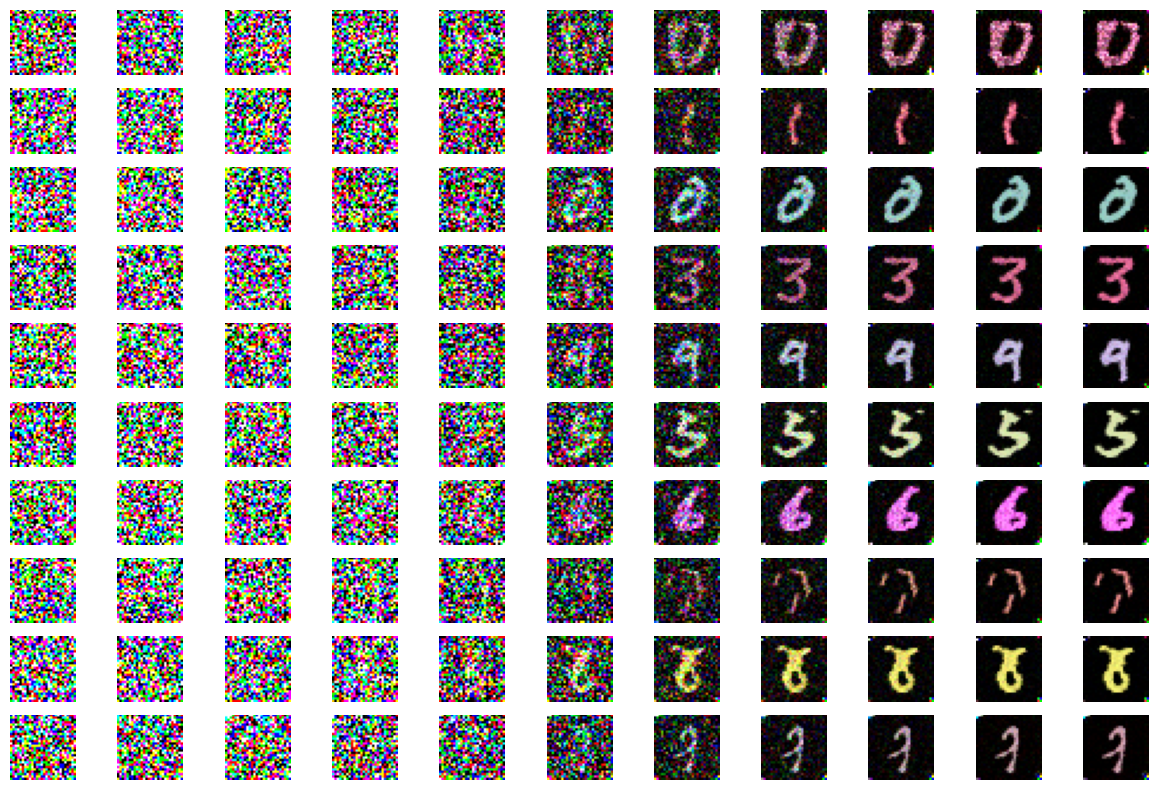

In [8]:
_ = plot_image_evolution(
    images=synthetic_images_t.detach().cpu(),
    n_images=n_images,
    # Pasos para n_steps=2000 (t va de 1.0 → 0.001)
    n_intermediate_steps=[0, 200, 400, 600, 800, 1000, 1200, 1400, 1600, 1800, 2000],
    figsize=(15, 10),
)


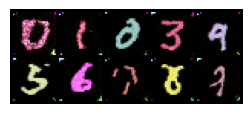

In [9]:
n_rows = 2
n_cols = 5

final_images = synthetic_images_t[..., -1].detach().cpu()

_ = plot_image_grid(
    images = final_images,
    figsize =(3, 3),
    n_rows=n_rows, 
    n_cols=n_cols,
)

In [ ]:
final_images = synthetic_images_t[..., -1]

# Calcular BPD para imágenes generadas con modelo condicional
with torch.no_grad():
    bpd_values = odec.compute_bpd_with_ode(
        model=score_model,
        x=final_images,  
        drift_coefficient=bm_drift_coefficient,
        diffusion_coefficient=diffusion_coefficient,
        sigma_t_func=bm_sigma_t,  
        y=y,
        n_steps=100,  
        seed=42
    )

print(f"\nBPD mean: {bpd_values.mean().item():.4f}")
print(f"BPD std: {bpd_values.std().item():.4f}")

/tmp/ipykernel_2881/964758059.py:9: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  t = torch.tensor(t)



BPD mean: 5.4474
BPD std: 1.2526
